In [1]:
import json
from pathlib import Path
from PIL import Image
from pykakasi import kakasi

In [2]:
ROOT = Path(
r"E:\japanread\dataset\raw\openmantra"
)

JSON_PATH = (
ROOT /
"annotation.json"
)

CROP_DIR = Path(
r"E:\japanread\dataset\raw\cropped"
)

OUT = Path(
r"E:\japanread\dataset\raw\processed\train.json"
)

In [3]:
with open(
JSON_PATH,
"r",
encoding="utf-8"
) as f:

    data = json.load(f)

print(
"Books:",
len(data)
)

Books: 5


In [4]:
book = data[0]

page = book["pages"][0]

text = page["text"][0]

print(text)

{'x': 82, 'y': 952, 'w': 668, 'h': 107, 'text_ja': '綴じ眼のシオラ', 'text_en': 'bound eye siora', 'text_zh': '縫眼的希奧拉'}


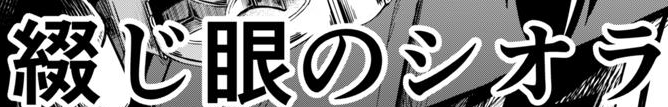

In [5]:
img = Image.open(
ROOT /
page["image_paths"]["ja"]
)

crop = img.crop(
(
text["x"],
text["y"],
text["x"]+text["w"],
text["y"]+text["h"]
)
)

crop

In [6]:
kks = kakasi()

result = (
kks.convert(
text["text_ja"]
)
)

furi = " ".join(
[
x["hira"]
for x in result
]
)

print(furi)

とじ め の しおら


In [8]:
target = (
f"<OCR>{text['text_ja']}"
f"<FURI>{furi}"
f"<TRANS>{text['text_en']}"
f"<EOS>"
)

print(target)

<OCR>綴じ眼のシオラ<FURI>とじ め の しおら<TRANS>bound eye siora<EOS>


In [8]:
import json
from pathlib import Path
from PIL import Image
from pykakasi import kakasi


# ----------------------
# PATHS
# ----------------------

ROOT = Path(
    r"E:\japanread\dataset\raw\openmantra"
)

JSON_PATH = (
    ROOT /
    "annotation.json"
)

CROP_DIR = Path(
    r"E:\japanread\dataset\raw\cropped"
)

OUT = Path(
    r"E:\japanread\dataset\raw\processed\train.json"
)


# ----------------------
# CREATE DIRS
# ----------------------

CROP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUT.parent.mkdir(
    parents=True,
    exist_ok=True
)


# ----------------------
# FURIGANA
# ----------------------

kks = kakasi()


def make_furi(jp):

    result = (
        kks.convert(jp)
    )

    return " ".join(
        [
            x["hira"]
            for x in result
        ]
    )


# ----------------------
# LOAD DATASET
# ----------------------

with open(
    JSON_PATH,
    "r",
    encoding="utf-8"
) as f:

    data = json.load(f)


dataset = []

counter = 0


# ----------------------
# BUILD
# ----------------------

for book in data:

    for page in book["pages"]:

        img = Image.open(
            ROOT /
            page["image_paths"]["ja"]
        )

        for text in page["text"]:

            try:

                x = text["x"]
                y = text["y"]
                w = text["w"]
                h = text["h"]

                jp = text["text_ja"]
                en = text["text_en"]


                # ----------------
                # CROP
                # ----------------

                crop = img.crop(
                    (
                        x,
                        y,
                        x + w,
                        y + h
                    )
                )


                # ----------------
                # KEEP RATIO
                # ----------------

               # ----------------
                # SMART RESIZE
                # ----------------

                TARGET = 256

                margin = 16


                scale = min(

                (TARGET - margin) /
                crop.width,

                (TARGET - margin) /
                crop.height

                )


                new_w = int(
                crop.width *
                scale
                )

                new_h = int(
                crop.height *
                scale
                )


                crop = crop.resize(
                (
                new_w,
                new_h
                )
                )

                canvas = Image.new(
                    "L",
                    (
                        256,
                        256
                    ),
                    255
                )

                ox = (
                    256
                    -
                    crop.width
                ) // 2

                oy = (
                    256
                    -
                    crop.height
                ) // 2

                canvas.paste(
                    crop,
                    (
                        ox,
                        oy
                    )
                )


                # ----------------
                # SAVE IMAGE
                # ----------------

                name = (
                    f"{counter:06}.jpg"
                )

                save = (
                    CROP_DIR /
                    name
                )

                canvas.save(
                    save
                )


                # ----------------
                # FURIGANA
                # ----------------

                furi = (
                    make_furi(
                        jp
                    )
                )


                # ----------------
                # TARGET
                # ----------------

                target = (
                    f"<OCR>{jp}"
                    f"<FURI>{furi}"
                    f"<TRANS>{en}"
                    f"<EOS>"
                )


                dataset.append(
                    {
                        "image": str(
                            save
                        ),

                        "target": target
                    }
                )


                counter += 1


            except Exception as e:

                print(
                    "\nERROR:"
                )

                print(
                    e
                )


# ----------------------
# SAVE JSON
# ----------------------

with open(
    OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset,
        f,
        ensure_ascii=False,
        indent=2
    )


# ----------------------
# DONE
# ----------------------

print("\nDONE\n")

print(
    "Samples:",
    counter
)

print(
    "\nSaved:"
)

print(
    OUT
)


DONE

Samples: 1592

Saved:
E:\japanread\dataset\raw\processed\train.json


In [9]:
with open(
OUT,
encoding="utf-8"
) as f:

    train = json.load(f)

train[0]

{'image': 'E:\\japanread\\dataset\\raw\\cropped\\000000.jpg',
 'target': '<OCR>綴じ眼のシオラ<FURI>とじ め の しおら<TRANS>bound eye siora<EOS>'}

In [ ]:
print(
"\nTotal Samples:\n"
)

print(
len(train)
);


Total Samples:

1592


In [11]:
import random


random.seed(
42
)


random.shuffle(
train
)


N = len(
train
)


train_end = int(
0.8 * N
)

val_end = int(
0.9 * N
)


train_split = (
train[
:train_end
]
)

val_split = (
train[
train_end:
val_end
]
)

test_split = (
train[
val_end:
]
)


print(
"\nTrain:",
len(
train_split
)
)

print(
"Val:",
len(
val_split
)
)

print(
"Test:",
len(
test_split
)
)


Train: 1273
Val: 159
Test: 160


In [12]:
import json


BASE = (
r"E:\japanread\dataset\raw\processed"
)


with open(
BASE +
"/train_split.json",
"w",
encoding="utf-8"
) as f:

    json.dump(
        train_split,
        f,
        ensure_ascii=False,
        indent=2
    )


with open(
BASE +
"/val_split.json",
"w",
encoding="utf-8"
) as f:

    json.dump(
        val_split,
        f,
        ensure_ascii=False,
        indent=2
    )


with open(
BASE +
"/test_split.json",
"w",
encoding="utf-8"
) as f:

    json.dump(
        test_split,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
"\nSplits Saved\n"
)


Splits Saved



In [13]:
FILES = [

r"E:\japanread\dataset\raw\processed\train_split.json",

r"E:\japanread\dataset\raw\processed\val_split.json"

]



SPECIAL = [

"<PAD>",
"<BOS>",
"<EOS>",

"<OCR>",
"<FURI>",
"<TRANS>",

"<UNK>"
]


VOCAB = set()


for file in FILES:

    with open(
        file,
        encoding="utf-8"
    ) as f:

        data = json.load(f)


    for sample in data:

        text = (
            sample[
                "target"
            ]
        )



        text = (
            text
            .replace(
                "<OCR>",
                ""
            )
            .replace(
                "<FURI>",
                ""
            )
            .replace(
                "<TRANS>",
                ""
            )
            .replace(
                "<EOS>",
                ""
            )
        )


        for c in text:

            VOCAB.add(
                c
            )


itos = (

SPECIAL

+

sorted(
VOCAB
)

)


stoi = {

v:i

for i,v

in enumerate(
itos
)

}


print(
"\nNew Vocab:"
)

print(
len(
stoi
)
)


New Vocab:
1024


In [14]:
print(

stoi[
"<PAD>"
]

)


print(

stoi[
"<OCR>"
]

)


print(

stoi[
"<FURI>"
]

)


print(

stoi[
"<TRANS>"
]

)


print(

stoi[
"<EOS>"
]

)

0
3
4
5
2


In [15]:
with open(
r"E:\japanread\tokenizer.json",
"w",
encoding="utf-8"
) as f:

    json.dump(
        stoi,
        f,
        ensure_ascii=False,
        indent=2
    )

print(
"Tokenizer Updated"
)

Tokenizer Updated


In [16]:
sample = (
train_split[
0
][
"target"
]
)


tokens = [

stoi.get(
c,
stoi[
"<UNK>"
]
)

for c

in sample

]


print(
sample
)

print()

print(
tokens[
:50
]
)

<OCR>月なき夜に道を外れてしまうこともあろう<FURI>がつ なき よる に みち を はずれ てしまうこともあろう<TRANS>at times, you may lose the track on a moonless night<EOS>

[6, 42, 30, 44, 6, 622, 127, 99, 425, 128, 940, 163, 423, 160, 123, 109, 146, 92, 105, 125, 150, 88, 161, 92, 6, 33, 47, 44, 36, 6, 98, 121, 8, 127, 99, 8, 156, 159, 8, 128, 8, 147, 119, 8, 163, 8, 132, 112, 160, 8]


In [17]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms


class MangaDataset(Dataset):

    def __init__(
        self,
        data,
        stoi,
        max_len=256
    ):

        self.data = data
        self.stoi = stoi
        self.max_len = max_len

        self.tf = transforms.Compose(
            [
                transforms.Grayscale(),
                transforms.ToTensor()
            ]
        )


    def encode(
        self,
        text
    ):

        ids = []

        i = 0

        while i < len(text):

            matched = False


            for s in [

                "<OCR>",
                "<FURI>",
                "<TRANS>",
                "<EOS>"

            ]:

                if text.startswith(
                    s,
                    i
                ):

                    ids.append(
                        self.stoi[s]
                    )

                    i += len(s)

                    matched = True

                    break


            if matched:

                continue


            ids.append(

                self.stoi.get(

                    text[i],

                    self.stoi["<UNK>"]

                )

            )

            i += 1


        ids = ids[:self.max_len]


        ids += [

            self.stoi["<PAD>"]

        ] * (

            self.max_len
            -
            len(ids)

        )


        return torch.tensor(
            ids
        )


    def __getitem__(
        self,
        idx
    ):

        item = (
            self.data[
                idx
            ]
        )


        img = Image.open(

            item[
                "image"
            ]

        ).convert(

            "L"

        )


        img = self.tf(
            img
        )


        target = self.encode(

            item[
                "target"
            ]

        )


        return (

            img,

            target

        )


    def __len__(
        self
    ):

        return len(
            self.data
        )

In [18]:
ds = MangaDataset(
    train_split,
    stoi
)

sample = ds.__getitem__(0)

print(type(sample))

img = sample[0]

tok = sample[1]

print(type(img))

print(type(tok))

print(img.shape)

print(tok.shape)

<class 'tuple'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([1, 256, 256])
torch.Size([256])


In [19]:
from torch.utils.data import DataLoader


loader = DataLoader(
    ds,
    batch_size=8,
    shuffle=True
)


imgs, toks = next(
    iter(loader)
)


print(
    imgs.shape
)

print(
    toks.shape
)

torch.Size([8, 1, 256, 256])
torch.Size([8, 256])


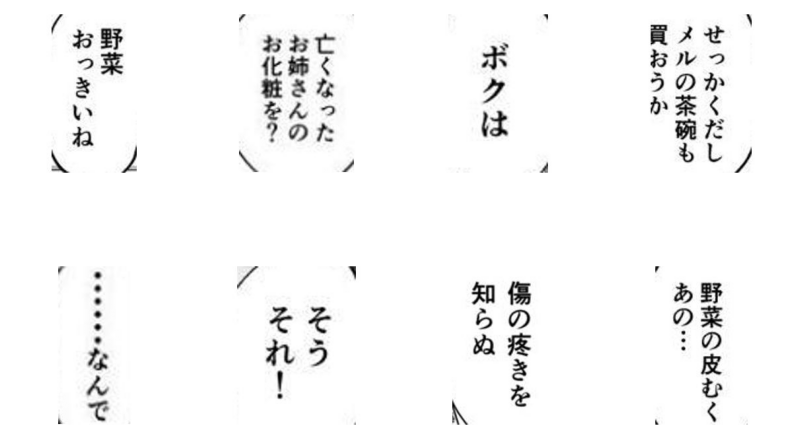

In [20]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(10,6)
)


for i in range(8):

    plt.subplot(
        2,
        4,
        i+1
    )

    plt.imshow(

        imgs[i][0],

        cmap="gray"

    )

    plt.axis(
        "off"
    )


plt.show()

In [21]:
import torch
import torch.nn as nn


class ResidualBlock(
    nn.Module
):

    def __init__(
        self,
        c
    ):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                c,
                c,
                3,
                padding=1
            ),

            nn.BatchNorm2d(
                c
            ),

            nn.GELU(),

            nn.Conv2d(
                c,
                c,
                3,
                padding=1
            ),

            nn.BatchNorm2d(
                c
            )

        )


    def forward(
        self,
        x
    ):

        return torch.relu(

            x +

            self.block(
                x
            )

        )



class Encoder(
    nn.Module
):

    def __init__(
        self
    ):

        super().__init__()


        self.net = nn.Sequential(

            nn.Conv2d(
                1,
                64,
                3,
                padding=1
            ),

            ResidualBlock(
                64
            ),

            nn.MaxPool2d(
                2
            ),


            nn.Conv2d(
                64,
                128,
                3,
                padding=1
            ),

            ResidualBlock(
                128
            ),

            nn.MaxPool2d(
                2
            ),


            nn.Conv2d(
                128,
                256,
                3,
                padding=1
            ),

            ResidualBlock(
                256
            ),

            nn.MaxPool2d(
                2
            ),


            nn.Conv2d(
                256,
                512,
                3,
                padding=1
            ),

            ResidualBlock(
                512
            )

        )


    def forward(
        self,
        x
    ):

        return self.net(
            x
        )

In [22]:
enc = Encoder()

out = enc(
imgs
)

print(
out.shape
)

torch.Size([8, 512, 32, 32])


In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class PPM(
    nn.Module
):

    def __init__(
        self,
        in_channels=512,
        out_channels=384
    ):

        super().__init__()


        self.scales = [

            1,

            2,

            4,

            8

        ]


        self.blocks = nn.ModuleList(

            [

                nn.Conv2d(

                    in_channels,

                    in_channels//4,

                    1

                )

                for _

                in self.scales

            ]

        )


        self.final = nn.Conv2d(

           1024,

            out_channels,

            1

        )


    def forward(
        self,
        x
    ):

        H,W = (

            x.shape[
                2:
            ]

        )


        features = [

            x

        ]


        for scale,block in zip(

            self.scales,

            self.blocks

        ):

            pooled = (

                F.adaptive_avg_pool2d(

                    x,

                    scale

                )

            )


            pooled = block(

                pooled

            )


            pooled = F.interpolate(

                pooled,

                size=(H,W),

                mode="bilinear",

                align_corners=False

            )


            features.append(

                pooled

            )


        x = torch.cat(

            features,

            dim=1

        )


        x = self.final(

            x

        )


        return x

In [24]:
ppm = PPM()

ppm_out = ppm(
out
)

print(
ppm_out.shape
)

torch.Size([8, 384, 32, 32])


In [25]:
import torch
import torch.nn as nn


class PatchGenerator(
    nn.Module
):

    def __init__(
        self,
        embed_dim=384
    ):

        super().__init__()


        self.patch = nn.Conv2d(

            embed_dim,

            embed_dim,

            kernel_size=2,

            stride=2

        )


    def forward(
        self,
        x
    ):


        x = self.patch(
            x
        )


        B,C,H,W = (
            x.shape
        )


        x = x.flatten(
            2
        )


        x = x.transpose(
            1,
            2
        )


        return x

In [26]:
patch = PatchGenerator()

patch_out = patch(
    ppm_out
)

print(
patch_out.shape
)

torch.Size([8, 256, 384])


In [27]:
import torch
import torch.nn as nn


class PositionalEncoding(
    nn.Module
):

    def __init__(
        self,
        max_len=256,
        dim=384
    ):

        super().__init__()


        self.pos = nn.Parameter(

            torch.randn(

                1,

                max_len,

                dim

            )

        )


    def forward(
        self,
        x
    ):

        return (

            x

            +

            self.pos[
                :,

                :
                x.shape[
                    1
                ]

            ]

        )

In [28]:
pos = PositionalEncoding()

memory = pos(
    patch_out
)

print(
memory.shape
)

torch.Size([8, 256, 384])


In [29]:
import torch


device = torch.device(

"cuda"

if torch.cuda.is_available()

else "cpu"

)

print(
device
)

cuda


In [30]:
import torch
import torch.nn as nn


class Decoder(
    nn.Module
):

    def __init__(
        self,
        vocab_size,
        dim=384,
        layers=4,
        heads=8,
        max_len=256
    ):

        super().__init__()

        self.embed = nn.Embedding(
            vocab_size,
            dim
        )

        self.pos = nn.Parameter(
            torch.randn(
                1,
                max_len,
                dim
            )
        )

        block = nn.TransformerDecoderLayer(
            d_model=dim,
            nhead=heads,
            batch_first=True
        )

        self.decoder = nn.TransformerDecoder(
            block,
            layers
        )

        self.out = nn.Linear(
            dim,
            vocab_size
        )


    def generate_square_subsequent_mask(
        self,
        sz,
        device
    ):

        mask = torch.triu(

            torch.ones(
                sz,
                sz,
                device=device
            ),

            diagonal=1

        )

        mask = mask.masked_fill(
            mask == 1,
            float("-inf")
        )

        return mask


    def forward(

        self,

        target,

        memory

    ):

        tgt_mask = (

            self.generate_square_subsequent_mask(

                target.shape[1],

                target.device

            )

        )


        target = self.embed(
            target
        )


        target = (

            target

            +

            self.pos[
                :,
                :
                target.shape[
                    1
                ]
            ]

        )


        x = self.decoder(

            target,

            memory,

            tgt_mask=tgt_mask

        )


        return self.out(
            x
        )

In [31]:
decoder = Decoder(

    vocab_size=len(
        stoi
    )

)


fake_target = toks


logits = decoder(

    fake_target,

    memory

)


print(
logits.shape
)

torch.Size([8, 256, 1024])


In [32]:
import torch
import torch.nn as nn


class JapanRead(
    nn.Module
):

    def __init__(
        self,
        vocab_size
    ):

        super().__init__()


        self.encoder = Encoder()

        self.ppm = PPM()

        self.patch = PatchGenerator()

        self.pos = PositionalEncoding()

        self.decoder = Decoder(
            vocab_size
        )


    def forward(

        self,

        image,

        target

    ):


        x = self.encoder(
            image
        )


        x = self.ppm(
            x
        )


        x = self.patch(
            x
        )


        memory = self.pos(
            x
        )


        out = self.decoder(

            target,

            memory

        )


        return out

In [33]:
model = JapanRead(

    vocab_size=len(
        stoi
    )

).to(
    device
)


imgs = imgs.to(
    device
)

toks = toks.to(
    device
)


decoder_in = (

    toks[
        :,
        :-
1
    ]

)


out = model(

    imgs,

    decoder_in

)


print(

"\nJapanRead v2 Ready"

)


print(

out.shape

)


JapanRead v2 Ready
torch.Size([8, 255, 1024])


In [34]:
criterion = nn.CrossEntropyLoss(

ignore_index=

stoi[
"<PAD>"
],

label_smoothing=0.1

)


pred = out.reshape(

-1,

len(
stoi
)

)


target = toks[
:,
1:
].reshape(
-1
)


loss = criterion(

pred,

target

)


print(

"Loss:",

loss.item()

)

Loss: 7.043337345123291


In [35]:
criterion = (

nn.CrossEntropyLoss(

ignore_index=

stoi[
"<PAD>"
]

)

)


pred = (

out.view(

-1,

len(
stoi
)

)

)


target = (

toks.view(
-1
)

)


loss = (

criterion(

pred,

target

)

)


print(
loss.item()
)

ValueError: Expected input batch_size (2040) to match target batch_size (2048).

In [36]:
optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=3e-5,

    weight_decay=1e-4

)


print(
"Optimizer Ready"
)

Optimizer Ready


In [37]:
model.train()


optimizer.zero_grad()


out = model(

    imgs,

    toks

)


pred = out.view(

    -1,

    len(
        stoi
    )

)


target = toks.view(
    -1
)


loss = criterion(

    pred,

    target

)


loss.backward()


optimizer.step()


print(
"\nTrain Loss:"
)

print(
loss.item()
)


Train Loss:
7.141674041748047


In [38]:
losses = []


imgs = imgs.to(
device
)

toks = toks.to(
device
)


for step in range(20):


    model.train()


    optimizer.zero_grad()


    decoder_in = (

        toks[
            :,
            :-
1
        ]

    )


    target = (

        toks[
            :,
            1:
        ]

    )


    out = model(

        imgs,

        decoder_in

    )


    pred = (

        out.reshape(

            -1,

            len(
                stoi
            )

        )

    )


    target = (

        target.reshape(
            -1
        )

    )


    loss = (

        criterion(

            pred,

            target

        )

    )


    loss.backward()


    optimizer.step()


    losses.append(

        loss.item()

    )


    print(

f"Step {step+1}: {loss.item():.4f}"

    )

Step 1: 6.8290
Step 2: 6.6137
Step 3: 6.4078
Step 4: 6.2274
Step 5: 6.0757
Step 6: 5.9516
Step 7: 5.8325
Step 8: 5.7478
Step 9: 5.6637
Step 10: 5.5905
Step 11: 5.5354
Step 12: 5.4624
Step 13: 5.4092
Step 14: 5.3412
Step 15: 5.2864
Step 16: 5.2461
Step 17: 5.2216
Step 18: 5.1591
Step 19: 5.1254
Step 20: 5.0894


In [43]:
from tqdm import tqdm


epochs = 30


for epoch in range(

    epochs

):


    model.train()


    total = 0


    for imgs,toks in tqdm(

        loader

    ):


        imgs = imgs.to(
            device
        )


        toks = toks.to(
            device
        )


        decoder_in = (

            toks[
                :,
                :-
1
            ]

        )


        target = (

            toks[
                :,
                1:
            ]

        )


        optimizer.zero_grad()


        out = model(

            imgs,

            decoder_in

        )


        pred = out.reshape(

            -1,

            len(
                stoi
            )

        )


        target = target.reshape(
            -1
        )


        loss = criterion(

            pred,

            target

        )


        loss.backward()


        optimizer.step()


        total += (
            loss.item()
        )


    avg = (

        total

        /

        len(
            loader
        )

    )


    print(

        f"\nEpoch {epoch+1}: {avg:.4f}"

    )

100%|██████████| 160/160 [01:08<00:00,  2.35it/s]



Epoch 1: 4.5762


100%|██████████| 160/160 [00:50<00:00,  3.19it/s]



Epoch 2: 3.6461


100%|██████████| 160/160 [00:52<00:00,  3.05it/s]



Epoch 3: 3.3481


... (50 outputs left out)

100%|██████████| 160/160 [00:56<00:00,  2.85it/s]



Epoch 29: 1.7576


100%|██████████| 160/160 [00:56<00:00,  2.86it/s]


Epoch 30: 1.6998


In [44]:
with open(
r"E:\japanread\dataset\raw\processed\val_split.json",
encoding="utf-8"
) as f:

    val = json.load(
        f
    )


val_ds = MangaDataset(

    val,

    stoi

)


val_loader = DataLoader(

    val_ds,

    batch_size=8

)


model.eval()


total = 0


with torch.no_grad():

    for imgs,toks in val_loader:


        imgs = imgs.to(
            device
        )


        toks = toks.to(
            device
        )


        decoder_in = (

            toks[
                :,
                :-
1
            ]

        )


        target = (

            toks[
                :,
                1:
            ]

        )


        out = model(

            imgs,

            decoder_in

        )


        pred = (

            out.reshape(

                -1,

                len(
                    stoi
                )

            )

        )


        target = (

            target.reshape(
                -1
            )

        )


        loss = criterion(

            pred,

            target

        )


        total += (

            loss.item()

        )


avg = (

    total

    /

    len(
        val_loader
    )

)


print(
"\nValidation Loss:"
)


print(
avg
)


Validation Loss:
2.7670484662055967


In [45]:
model.eval()


sample = val_ds[0]


img = (

sample[0]

.unsqueeze(0)

.to(
device
)

)


tok = (

sample[1]

.unsqueeze(0)

.to(
device
)

)


with torch.no_grad():

    decoder_in = (

        tok[
            :,
            :-
1
        ]

    )


    out = model(

        img,

        decoder_in

    )


pred = (

out

.argmax(
-1
)

)


print(
"\nPRED:\n"
)

print(

decode(
pred[0]
)

)


print(
"\nREAL:\n"
)

print(

decode(
tok[0]
)

)


PRED:

私は見はたくンくヤに<FURI>たで<FURI>たくで<FURI><FURI>お  を を い をくたしく たを たでょででうたでしで<TRANS>よI tetl   tnwet tntae tenle  t  hati th <EOS>

REAL:

<OCR>親を殺したマフィアを撃ち殺したんです<FURI>おや を ころし た まふぃあ を うち ころし たんです<TRANS>I killed a mafia who killed my parents.<EOS>


In [40]:
model.eval()


sample = val_ds[0]


img = (

sample[0]

.unsqueeze(0)

.to(
device
)

)


tok = (

sample[1]

.unsqueeze(0)

.to(
device
)

)


with torch.no_grad():

    decoder_in = (

        tok[
            :,
            :-
1
        ]

    )


    out = model(

        img,

        decoder_in

    )


pred = (

out

.argmax(
-1
)

)


print(

pred[
0
][
:40
]

)

print()


print(

tok[
0
][
:40
]

)

tensor([16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,  8, 16,  8,  8, 16,  8,
         8,  8, 16,  8, 16, 16, 16,  8,  8,  8, 16,  8, 16, 16,  8,  8, 16, 16,
         8,  8,  8,  8], device='cuda:0')

tensor([  3, 875, 163, 661, 109, 117, 212, 206, 167, 166, 163, 588, 119, 661,
        109, 117, 164, 124, 111,   4,  96, 152,   8, 163,   8, 105, 161, 109,
          8, 117,   8, 146, 138,  89,  88,   8, 163,   8,  92, 119],
       device='cuda:0')


In [41]:
itos = {

v:k

for k,v

in stoi.items()

}


def decode(
    ids
):

    out = []


    for i in ids:


        i = int(
            i
        )


        token = itos.get(

            i,

            ""

        )


        if token == "<PAD>":

            break


        out.append(
            token
        )


        if token == "<EOS>":

            break


    return "".join(
        out
    )



print(
"\nPRED:\n"
)


print(

decode(
pred[0]
)

)


print(
"\nREAL:\n"
)


print(

decode(
tok[0]
)

)


PRED:

............ .  .   . ...   . ..  ..      .   .   ..     .. .         ..   ......    .  .  ..    ... . . .   .. . ..       . ... ..  . ...   .    . ... ...     . .  . ....      .  ....... ... .. . . ... .    ..   .  .. . ..   .... ..  .      . .. ..  ..  

REAL:

<OCR>親を殺したマフィアを撃ち殺したんです<FURI>おや を ころし た まふぃあ を うち ころし たんです<TRANS>I killed a mafia who killed my parents.<EOS>


In [42]:
sample = val_ds[0]


img = sample[0].unsqueeze(
0
).to(
device
)

tok = sample[1].unsqueeze(
0
).to(
device
)


model.eval()


with torch.no_grad():

    decoder_in = tok[:,:-1]

    out = model(

        img,

        decoder_in

    )



pred = out.argmax(
-1
)



print(
decode(
pred[0]
)
)


print(
"\nREAL:\n"
)


print(
decode(
tok[0]
))

............ .  .   . ...   . ..  ..      .   .   ..     .. .         ..   ......    .  .  ..    ... . . .   .. . ..       . ... ..  . ...   .    . ... ...     . .  . ....      .  ....... ... .. . . ... .    ..   .  .. . ..   .... ..  .      . .. ..  ..  

REAL:

<OCR>親を殺したマフィアを撃ち殺したんです<FURI>おや を ころし た まふぃあ を うち ころし たんです<TRANS>I killed a mafia who killed my parents.<EOS>
